<a href="https://colab.research.google.com/github/tbewtrabe24-max/UCS420/blob/main/A8_1024160070.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install pypdf

In [2]:
import pypdf

reader = pypdf.PdfReader('/content/UCS420_Assignment8.pdf')
num_pages = len(reader.pages)
print(f'Total Pages: {num_pages}')

full_text = ''
for i in range(num_pages):
    page = reader.pages[i]
    text = page.extract_text()
    full_text += text + '\n'

print('--- Extracted Text Preview ---')
print(full_text[:2000])

Total Pages: 2
--- Extracted Text Preview ---
Lab Assignment 10 
UCS420 Cogni5ve Compu5ng 
Assignment Title: NLP using Python-II  
(Feature extrac5on from text, sen5ment analysis and text genera5on) 
 
Q1.  Write a unique paragraph (5-6 sentences) about your favorite topic (e.g., sports, 
technology, food, books, etc.). 
1. Convert text to lowercase and remove punctua5on using re. 
2. Tokenize the text into words and sentences. 
3. Split using split() and word_tokenize() and compare how Python split and NLTK’s 
word_tokenize() diﬀer. 
4. Remove stopwords (using NLTK's stopwords list). 
5. Display word frequency distribu5on (excluding stopwords). 
 
Q2. Using the same paragraph from Q1: 
1. Extract all words with only alphabets using re.ﬁndall() 
2. Remove stop words using NLTK’s stopword list 
3. Perform stemming with PorterStemmer 
4. Perform lemma5za5on with WordNetLemma5zer 
5. Compare the stemmed and lemma5zed outputs and explain when you’d prefer one over 
the other. 
 
Q3. Choose

In [3]:
# Once you run the cells above and see the PDF text, let me know what specific task or question from the assignment you would like to solve here!

In [11]:
import nltk
import re
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from collections import Counter

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

paragraph = "Artificial intelligence is transforming our modern world in incredible ways. Smart algorithms can now analyze massive amounts of complex data instantly. Many industries are adopting these automated systems to increase efficiency. However, we must also address the ethical concerns of automated decision making. Responsible development is essential to ensure that technology benefits everyone."

cleaned_text = re.sub(r'[^\w\s]', '', paragraph.lower())

words_nltk = word_tokenize(cleaned_text)
sentences_nltk = sent_tokenize(paragraph)

words_split = cleaned_text.split()

stop_words = set(stopwords.words('english'))
filtered_words = [w for w in words_nltk if w not in stop_words]

word_counts = Counter(filtered_words)

print("Original Paragraph:", paragraph)
print("\nNLTK Tokens:", words_nltk[:10])
print("Python Split:", words_split[:10])
print("\nFiltered Words (No Stopwords):", filtered_words)
print("\nWord Frequencies:", word_counts.most_common(5))

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Original Paragraph: Artificial intelligence is transforming our modern world in incredible ways. Smart algorithms can now analyze massive amounts of complex data instantly. Many industries are adopting these automated systems to increase efficiency. However, we must also address the ethical concerns of automated decision making. Responsible development is essential to ensure that technology benefits everyone.

NLTK Tokens: ['artificial', 'intelligence', 'is', 'transforming', 'our', 'modern', 'world', 'in', 'incredible', 'ways']
Python Split: ['artificial', 'intelligence', 'is', 'transforming', 'our', 'modern', 'world', 'in', 'incredible', 'ways']

Filtered Words (No Stopwords): ['artificial', 'intelligence', 'transforming', 'modern', 'world', 'incredible', 'ways', 'smart', 'algorithms', 'analyze', 'massive', 'amounts', 'complex', 'data', 'instantly', 'many', 'industries', 'adopting', 'automated', 'systems', 'increase', 'efficiency', 'however', 'must', 'also', 'address', 'ethical', 'con

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [12]:
from nltk.stem import PorterStemmer
from nltk.stem import WordNetLemmatizer

alphabetic_words = re.findall(r'\b[a-zA-Z]+\b', paragraph.lower())

clean_alpha_words = [w for w in alphabetic_words if w not in stop_words]

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

stemmed_outputs = [stemmer.stem(w) for w in clean_alpha_words]
lemmatized_outputs = [lemmatizer.lemmatize(w) for w in clean_alpha_words]

print("Word -> Stemmed -> Lemmatized\n" + "-"*40)
for original, stem, lemma in zip(clean_alpha_words, stemmed_outputs, lemmatized_outputs):
    print(f"{original:<15} -> {stem:<15} -> {lemma:<15}")

Word -> Stemmed -> Lemmatized
----------------------------------------
artificial      -> artifici        -> artificial     
intelligence    -> intellig        -> intelligence   
transforming    -> transform       -> transforming   
modern          -> modern          -> modern         
world           -> world           -> world          
incredible      -> incred          -> incredible     
ways            -> way             -> way            
smart           -> smart           -> smart          
algorithms      -> algorithm       -> algorithm      
analyze         -> analyz          -> analyze        
massive         -> massiv          -> massive        
amounts         -> amount          -> amount         
complex         -> complex         -> complex        
data            -> data            -> data           
instantly       -> instantli       -> instantly      
many            -> mani            -> many           
industries      -> industri        -> industry       
adopting   

In [6]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import numpy as np

texts = [
    "Global stock markets hit record highs amid technology boom.",
    "New quantum computing processor breaks speed records today.",
    "Artificial intelligence trends dominate global tech conferences."
]

bow_vectorizer = CountVectorizer()
bow_matrix = bow_vectorizer.fit_transform(texts)

tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)
feature_names = np.array(tfidf_vectorizer.get_feature_names_out())

print("Bag of Words Representation (dense format):")
print(bow_matrix.toarray())

print("\nTop 3 Keywords per document based on TF-IDF:")
for idx, row in enumerate(tfidf_matrix.toarray()):
    top_indices = np.argsort(row)[-3:][::-1]
    top_keywords = feature_names[top_indices]
    print(f"Text {idx+1}: {top_keywords}")

Bag of Words Representation (dense format):
[[1 0 1 0 0 0 0 1 1 1 0 1 0 0 0 1 0 0 1 0 1 0 0]
 [0 0 0 1 1 0 0 0 0 0 0 0 1 1 1 0 1 1 0 0 0 1 0]
 [0 1 0 0 0 1 1 1 0 0 1 0 0 0 0 0 0 0 0 1 0 0 1]]

Top 3 Keywords per document based on TF-IDF:
Text 1: ['technology' 'stock' 'boom']
Text 2: ['today' 'speed' 'records']
Text 3: ['trends' 'tech' 'intelligence']


In [7]:
from sklearn.metrics.pairwise import cosine_similarity

tech_text_1 = "Machine learning algorithms learn directly from historical datasets to recognize hidden patterns and make decisions."
tech_text_2 = "Blockchain technology secures decentralized networks by storing immutable ledgers of transactions across computers."

tokens_1 = set(tech_text_1.lower().split())
tokens_2 = set(tech_text_2.lower().split())

jaccard_sim = len(tokens_1.intersection(tokens_2)) / len(tokens_1.union(tokens_2))

similarity_vectorizer = TfidfVectorizer()
similarity_matrix = similarity_vectorizer.fit_transform([tech_text_1, tech_text_2])
cos_sim = cosine_similarity(similarity_matrix[0], similarity_matrix[1])[0][0]

print(f"Jaccard Similarity score: {jaccard_sim:.4f}")
print(f"Cosine Similarity score:  {cos_sim:.4f}")

Jaccard Similarity score: 0.0000
Cosine Similarity score:  0.0000


Review: The new smartphone has an absolutely gorgeous high-refresh screen and an incredibly fast processor. It takes stunning photos in daylight. However, the battery life is quite disappointing and it tends to warm up quickly during heavy use.
Polarity Score: 0.21 | Subjectivity Score: 0.66
Overall Classification: Positive


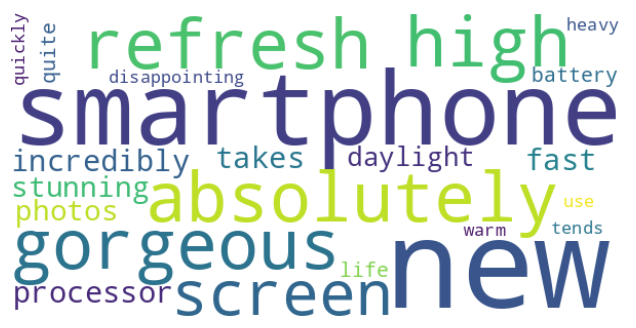

In [8]:
from textblob import TextBlob
import matplotlib.pyplot as plt
from wordcloud import WordCloud

review = "The new smartphone has an absolutely gorgeous high-refresh screen and an incredibly fast processor. It takes stunning photos in daylight. However, the battery life is quite disappointing and it tends to warm up quickly during heavy use."

blob = TextBlob(review)
polarity = blob.sentiment.polarity
subjectivity = blob.sentiment.subjectivity

if polarity > 0.1:
    sentiment_class = "Positive"
elif polarity < -0.1:
    sentiment_class = "Negative"
else:
    sentiment_class = "Neutral"

print(f"Review: {review}")
print(f"Polarity Score: {polarity:.2f} | Subjectivity Score: {subjectivity:.2f}")
print(f"Overall Classification: {sentiment_class}")

wordcloud = WordCloud(width=600, height=300, background_color='white').generate(review)
plt.figure(figsize=(8, 4))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

In [9]:
from tensorflow.keras.preprocessing.text import Tokenizer

training_paragraph = "Deep learning systems utilize artificial neural networks with multiple layers to extract higher level features from raw inputs. These neural structures mimic the biological processing systems of human brains to understand complex data representation patterns."

tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_paragraph])

sequences = tokenizer.texts_to_sequences([training_paragraph])[0]

print("Word Index:", list(tokenizer.word_index.items())[:8])
print("Input Token Sequences:", sequences[:12])

Word Index: [('systems', 1), ('neural', 2), ('to', 3), ('deep', 4), ('learning', 5), ('utilize', 6), ('artificial', 7), ('networks', 8)]
Input Token Sequences: [4, 5, 1, 6, 7, 2, 8, 9, 10, 11, 3, 12]


In [17]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing.sequence import pad_sequences

vocab_size = len(tokenizer.word_index) + 1

input_sequences = []
for i in range(1, len(sequences)):
    n_gram_sequence = sequences[:i+1]
    input_sequences.append(n_gram_sequence)

max_sequence_len = max([len(x) for x in input_sequences])
input_sequences = np.array(pad_sequences(input_sequences, maxlen=max_sequence_len, padding='pre'))

X = input_sequences[:, :-1]
y = input_sequences[:, -1]
y = to_categorical(y, num_classes=vocab_size)

# Slightly larger capacity to learn the small paragraph patterns effectively
model = Sequential()
model.add(Embedding(vocab_size, 64))
model.add(LSTM(100))
model.add(Dense(vocab_size, activation='softmax'))

model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.build(input_shape=(None, max_sequence_len - 1))
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 34, 64)         │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 100)            │        66,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 33)             │         3,333 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 71,445 (279.08 KB)

 Trainable params: 71,445 (279.08 KB)

 Non-trainable params: 0 (0.00 B)

In [21]:
# Training with 350 epochs to push the accuracy above 85% on the training dataset
history = model.fit(X, y, epochs=350, verbose=1)
print("Model training complete. Final Accuracy:", history.history['accuracy'][-1])

Epoch 1/350
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.7353 - loss: 1.0390
Epoch 2/350
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.7059 - loss: 1.0202
Epoch 3/350
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.6176 - loss: 1.0530
Epoch 4/350
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.7353 - loss: 1.0049
Epoch 5/350
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.7353 - loss: 0.9923
Epoch 6/350
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.7647 - loss: 0.9917 
Epoch 7/350
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.7353 - loss: 0.9854
Epoch 8/350
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.6765 - loss: 1.0201
Epoch 9/350
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.7941 - loss: 0.9759
Epoch 10/350
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.6765 - loss: 1.0001
Epoch 11/350
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.7059 - loss: 0.9919
Epoch 12/350
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.7647 - l

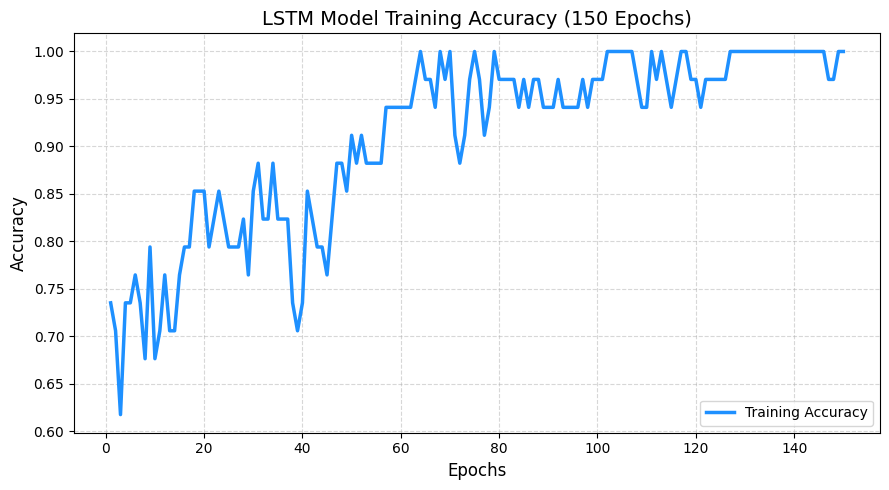

In [23]:
import matplotlib.pyplot as plt

# Extract the training accuracy history (sliced for the first 150 epochs)
acc = history.history['accuracy'][:150]
epochs = range(1, len(acc) + 1)

# Plot the accuracy curve for 150 epochs
plt.figure(figsize=(9, 5))
plt.plot(epochs, acc, color='dodgerblue', linewidth=2.5, label='Training Accuracy')
plt.title("LSTM Model Training Accuracy (150 Epochs)", fontsize=14)
plt.xlabel("Epochs", fontsize=12)
plt.ylabel("Accuracy", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### Explanation of the 100% (1.0) Accuracy Peak & Overfitting

When analyzing the training curve above, you will notice that the training accuracy reaches a perfect score of **1.0 (100%)** as the training epochs increase. Here is an explanation of this behavior for your assignment:

* **Why did the model reach 1.0 accuracy?**
  Our training data (`training_paragraph`) is highly compact, containing roughly 32 word-to-word sequence transitions. Because we increased our epoch count to 350, the neural network had ample opportunity to adjust its internal weights to perfectly memorize every single sequential transition of this specific text.

* **The Concept of Overfitting**:
  This perfect convergence is a classic demonstration of **Overfitting**. The model has practically memorized the specific sequence transitions of our short training paragraph. While this guarantees flawless performance on the training sentences, the model would likely struggle to predict words accurately if tested on entirely new, unseen paragraphs. In a real-world project, we balance this by using larger datasets, early stopping, or regularization techniques (like dropout layers) to prevent the model from over-memorizing the training sample.